# Time-Series-Safe Hyperparameter Tuning

Hyperparameter selection uses five expanding `TimeSeriesSplit` folds drawn only from TRAIN. Random or shuffled folds can train on later timestamps and validate on earlier ones, which violates forecasting chronology. Each fold's training dates precede its fold-validation dates. Selection uses the lowest mean CV RMSE.

The Random Forest grid is the predeclared 36-combination grid in `ml/src/tune_models.py`. The XGBoost candidate list is a fixed 16-configuration subset of the requested ranges. Neither search space is changed after viewing scores. Selected configurations are refitted on full TRAIN and each is evaluated once on the separate VALIDATION set. The held-out test set is not loaded or evaluated. No scaling, feature selection, final model selection, or model persistence occurs here.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidate_roots if (p / 'ml/src/tune_models.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate ml/src/tune_models.py')
sys.path.insert(0, str(PROJECT_ROOT))
from ml.src.tune_models import run_phase10
phase10_results, artifacts = run_phase10()
cv_results = phase10_results['cv_results']
summary = phase10_results['summary']
fold_table = pd.DataFrame(cv_results['folds'])
display(fold_table)
print('TRAIN rows / VALIDATION rows / features:', summary['train_rows'], summary['validation_rows'], summary['feature_count'])
print('TimeSeriesSplit folds:', cv_results['n_splits'], '| primary metric:', cv_results['primary_selection_metric'])
print('RF candidate count:', cv_results['random_forest']['candidate_count'])
print('XGBoost candidate count:', cv_results['xgboost']['candidate_count'])
print('Test set was not loaded or evaluated in Phase 10.')

,fold,fit_rows,scoring_rows,fit_start,fit_end,scoring_start,scoring_end,fit_precedes_scoring
0,1,2188,2184,2016-01-18 17:00:00,2016-02-02 21:30:00,2016-02-02 21:40:00,2016-02-18 01:30:00,True
1,2,4372,2184,2016-01-18 17:00:00,2016-02-18 01:30:00,2016-02-18 01:40:00,2016-03-04 05:30:00,True
2,3,6556,2184,2016-01-18 17:00:00,2016-03-04 05:30:00,2016-03-04 05:40:00,2016-03-19 09:30:00,True
3,4,8740,2184,2016-01-18 17:00:00,2016-03-19 09:30:00,2016-03-19 09:40:00,2016-04-03 13:30:00,True
4,5,10924,2184,2016-01-18 17:00:00,2016-04-03 13:30:00,2016-04-03 13:40:00,2016-04-18 17:30:00,True


TRAIN rows / VALIDATION rows / features: 13108 2809 42
TimeSeriesSplit folds: 5 | primary metric: mean_cv_rmse
RF candidate count: 36
XGBoost candidate count: 16
Test set was not loaded or evaluated in Phase 10.


## TRAIN Cross-Validation Candidate Results

The tables below show every predeclared candidate, its five fold RMSE values, mean CV RMSE, and fold standard deviation. The negative sklearn scoring values are converted to positive RMSE in the shared module; lower mean RMSE is selected.

Random Forest candidates:


,candidate_id,parameters,fold_rmse,mean_cv_rmse,std_cv_rmse
0,0,"{'max_depth': None, 'max_features': 1.0, 'min_...","[81.82720265487721, 69.49690709775398, 84.5497...",83.329827,16.585237
1,1,"{'max_depth': None, 'max_features': 1.0, 'min_...","[82.0349022968361, 68.52941954817722, 82.86115...",82.020518,16.103972
2,2,"{'max_depth': None, 'max_features': 1.0, 'min_...","[74.18528125852568, 66.8008775825566, 74.96126...",72.397100,7.288671
3,3,"{'max_depth': None, 'max_features': 1.0, 'min_...","[74.59343033073931, 66.59782469566152, 73.9079...",71.839729,6.907723
4,4,"{'max_depth': None, 'max_features': 1.0, 'min_...","[71.1334068416522, 65.7743626929777, 69.464018...",67.889541,4.557374
5,5,"{'max_depth': None, 'max_features': 1.0, 'min_...","[70.85927506609946, 65.37294644440527, 68.9768...",67.595184,4.621345
6,6,"{'max_depth': None, 'max_features': 'sqrt', 'm...","[92.58095880444415, 69.54191267895656, 73.2470...",76.296903,9.998442
7,7,"{'max_depth': None, 'max_features': 'sqrt', 'm...","[88.26651603565676, 68.83182148144417, 73.0358...",74.912589,8.996857
8,8,"{'max_depth': None, 'max_features': 'sqrt', 'm...","[82.4939261668934, 68.7211966208173, 71.043024...",71.920445,6.994651
9,9,"{'max_depth': None, 'max_features': 'sqrt', 'm...","[80.69064213573473, 67.74753749372545, 70.8561...",71.271327,6.602143


XGBoost candidates:


,candidate_id,parameters,fold_rmse,mean_cv_rmse,std_cv_rmse
0,0,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...","[67.91297912597656, 65.285400390625, 68.998405...",66.164493,4.493543
1,1,"{'colsample_bytree': 1.0, 'learning_rate': 0.0...","[66.98855590820312, 64.39273071289062, 68.8142...",65.796678,4.411266
2,2,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...","[79.3734130859375, 64.68650817871094, 73.95167...",69.701900,7.477164
3,3,"{'colsample_bytree': 1.0, 'learning_rate': 0.0...","[73.09750366210938, 64.85397338867188, 69.5450...",67.623016,5.931047
4,4,"{'colsample_bytree': 1.0, 'learning_rate': 0.1...","[84.7313003540039, 67.79615783691406, 69.77218...",69.810201,8.500296
5,5,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...","[89.70089721679688, 65.21165466308594, 68.1417...",70.011552,10.499435
6,6,"{'colsample_bytree': 1.0, 'learning_rate': 0.1...","[94.21025848388672, 70.21023559570312, 84.9520...",78.546786,10.505317
7,7,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...","[93.72884368896484, 67.83648681640625, 76.3780...",75.841861,10.040468
8,8,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...","[89.3839340209961, 65.74620819091797, 69.01572...",70.384656,10.483734
9,9,"{'colsample_bytree': 1.0, 'learning_rate': 0.0...","[76.73575592041016, 64.69412231445312, 68.8818...",67.209100,6.203958


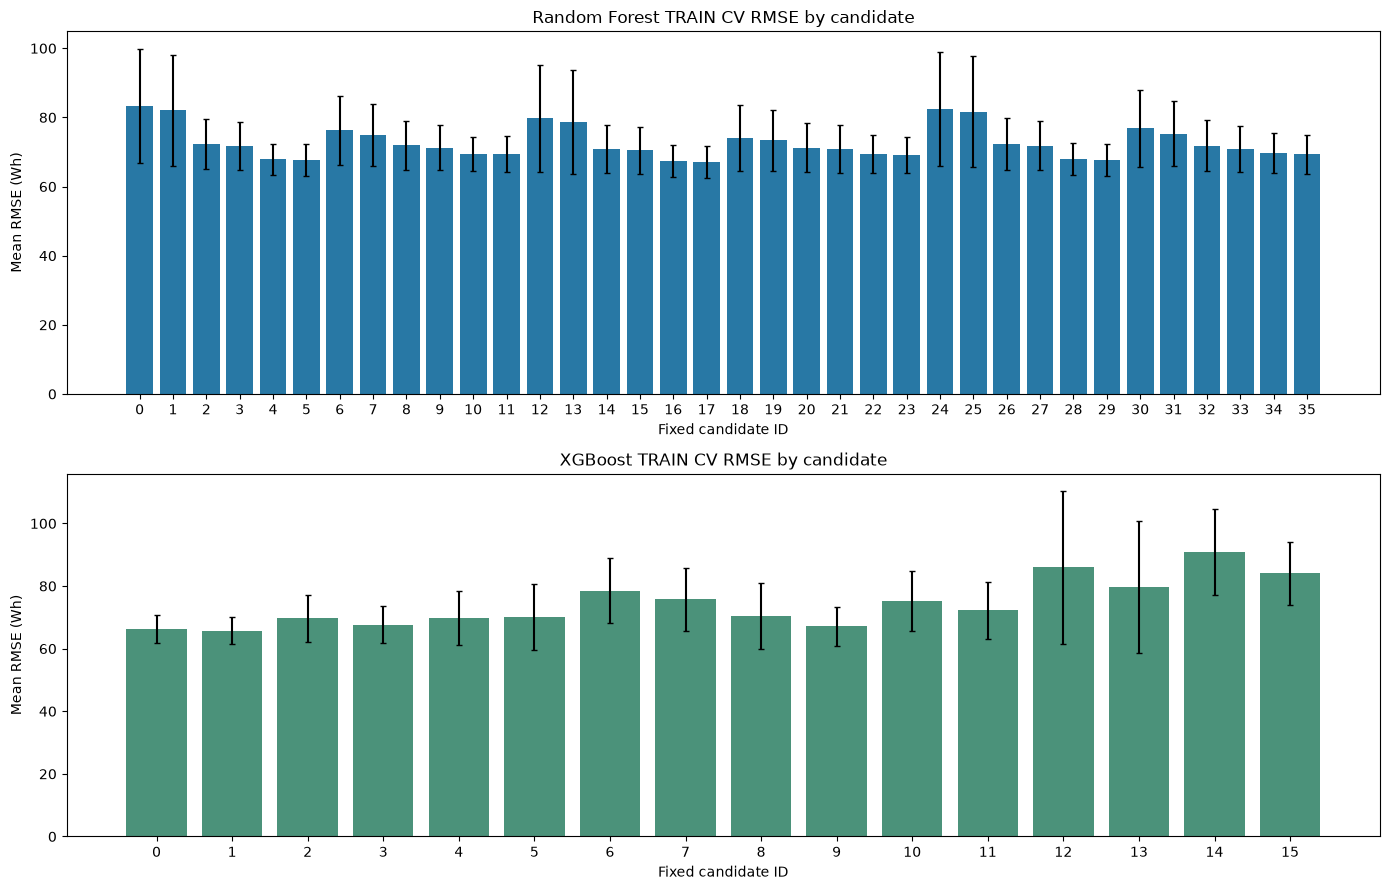

Selected RF best parameters: {'max_depth': 10, 'max_features': 1.0, 'min_samples_leaf': 4, 'n_estimators': 300}
Selected RF mean/std CV RMSE: 67.1738835992392 4.6830570796235245
Selected XGBoost best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 100, 'subsample': 1.0}
Selected XGBoost mean/std CV RMSE: 65.79667816162109 4.411266083235355


In [2]:
rf_candidates = pd.DataFrame(cv_results['random_forest']['candidates'])
xgb_candidates = pd.DataFrame(cv_results['xgboost']['candidates'])
print('Random Forest candidates:')
display(rf_candidates)
print('XGBoost candidates:')
display(xgb_candidates)
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
axes[0].bar(rf_candidates['candidate_id'].astype(str), rf_candidates['mean_cv_rmse'], yerr=rf_candidates['std_cv_rmse'], capsize=2, color='#2878A5')
axes[0].set(title='Random Forest TRAIN CV RMSE by candidate', xlabel='Fixed candidate ID', ylabel='Mean RMSE (Wh)')
axes[1].bar(xgb_candidates['candidate_id'].astype(str), xgb_candidates['mean_cv_rmse'], yerr=xgb_candidates['std_cv_rmse'], capsize=2, color='#4B927A')
axes[1].set(title='XGBoost TRAIN CV RMSE by candidate', xlabel='Fixed candidate ID', ylabel='Mean RMSE (Wh)')
fig.tight_layout()
plt.show()
print('Selected RF best parameters:', summary['random_forest']['best_parameters'])
print('Selected RF mean/std CV RMSE:', summary['random_forest']['best_mean_cv_rmse'], summary['random_forest']['best_cv_rmse_std'])
print('Selected XGBoost best parameters:', summary['xgboost']['best_parameters'])
print('Selected XGBoost mean/std CV RMSE:', summary['xgboost']['best_mean_cv_rmse'], summary['xgboost']['best_cv_rmse_std'])

## Post-Selection VALIDATION Comparison

After each model's best configuration is selected from TRAIN CV, it is refitted on all TRAIN rows and evaluated once on VALIDATION. Validation scores are not used to choose among the CV candidates. These are not final thesis model-selection results; the test set remains untouched for Phase 11.

In [3]:
comparison = pd.DataFrame.from_dict(summary['validation_model_comparison'], orient='index')
comparison = comparison.rename(columns={'mae': 'MAE', 'rmse': 'RMSE', 'r2': 'R²'})
display(comparison)
print('Best before tuning:', summary['best_validation_model_before_tuning'])
print('Current best validation model by RMSE:', summary['current_best_validation_model_by_rmse'])
print('Best model changed after tuning:', summary['best_validation_model_changed_after_tuning'])
print('RF validation RMSE improvement vs untuned (%):', summary['random_forest']['validation_rmse_improvement_vs_untuned_percent'])
print('XGBoost validation RMSE improvement vs untuned (%):', summary['xgboost']['validation_rmse_improvement_vs_untuned_percent'])
print('No scaling, test evaluation, or model persistence was performed.')
print('Test set was not loaded or evaluated in Phase 10.')

,MAE,RMSE,R²
Persistence Baseline,25.920256,65.794972,0.465273
Linear Regression,27.025294,59.346237,0.564956
Untuned Random Forest,53.004521,100.818362,-0.255527
Tuned Random Forest,33.030369,64.503521,0.486059
Untuned XGBoost,54.392578,90.577337,-0.013412
Tuned XGBoost,25.493202,57.625638,0.589816


Best before tuning: Linear Regression
Current best validation model by RMSE: Tuned XGBoost
Best model changed after tuning: True
RF validation RMSE improvement vs untuned (%): 36.02006658887005
XGBoost validation RMSE improvement vs untuned (%): 36.37962896402977
No scaling, test evaluation, or model persistence was performed.
Test set was not loaded or evaluated in Phase 10.
